# Koding 5 Prompt Geofisika
**Nama:** SYARIF MUYASSAR  
**NIM:** H061251019

Kode menggunakan data contoh/sintetis agar dapat dijalankan tanpa file data lapangan. Ganti bagian data contoh dengan dataset asli jika tersedia.

## Prompt 1 — Interpretasi Data Magnetik
Tujuan: memeriksa data, membuat peta sebaran anomali, dan menandai anomali relatif tinggi/rendah. Interpretasi sumber geologi tidak ditetapkan hanya dari nilai anomali.

            X           Y  anomali_nT
0  771.320643  578.136430   63.590665
1   20.751949  853.933751   -0.882553
2  633.648235   68.097274   20.474195
3  748.803883  464.530808   82.627221
4  498.507012  781.949119    0.070334
count    100.000000
mean      19.521619
std       35.658671
min      -54.368865
25%       -2.611433
50%       10.858913
75%       36.917137
max      128.353964
Name: anomali_nT, dtype: float64
Jumlah data kosong: 0


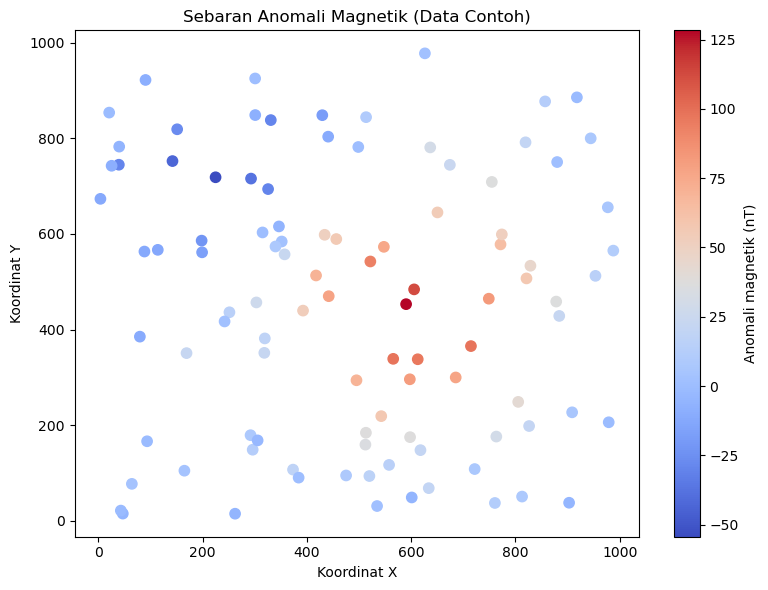

10 anomali tertinggi:
             X           Y  anomali_nT
63  590.201363  453.105000  128.353964
80  605.577564  484.020890  112.000930
89  565.507020  338.679133   97.921317
19  714.575783  365.364971   97.776767
15  612.526067  337.815887   96.897028
31  521.647152  542.408516   92.929824
3   748.803883  464.530808   82.627221
60  597.371648  295.903762   80.874056
24  441.833174  469.785293   78.281728
10  685.359818  299.729872   77.639769
10 anomali terendah:
             X           Y  anomali_nT
5   224.796646  718.602810  -54.368865
21  142.170048  752.496170  -42.965447
91  292.797976  715.830873  -37.498862
48  325.511638  693.890066  -30.237165
68  330.719312  838.261321  -29.989789
64   39.281767  744.864077  -29.827573
53  151.152020  819.035864  -26.734890
6   198.062865  586.021980  -22.850739
71  429.492178  848.509182  -18.021874
42  198.947540  561.557360  -16.579640
Interpretasi awal: pola tinggi/rendah menunjukkan variasi magnetik.
Penentuan litologi atau sumber 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DATA CONTOH: ganti dengan file data sendiri jika tersedia
np.random.seed(10)
n = 100
df_mag = pd.DataFrame({
    "X": np.random.uniform(0, 1000, n),
    "Y": np.random.uniform(0, 1000, n),
})
# Contoh anomali sintetis, satuan nT
df_mag["anomali_nT"] = (120*np.exp(-((df_mag.X-600)**2+(df_mag.Y-450)**2)/(2*180**2))
                        - 55*np.exp(-((df_mag.X-250)**2+(df_mag.Y-700)**2)/(2*130**2))
                        + np.random.normal(0, 8, n))

print(df_mag.head())
print(df_mag["anomali_nT"].describe())
print("Jumlah data kosong:", df_mag.isna().sum().sum())

# Peta sebaran anomali
plt.figure(figsize=(8, 6))
sc = plt.scatter(df_mag.X, df_mag.Y, c=df_mag.anomali_nT, cmap="coolwarm", s=55)
plt.colorbar(sc, label="Anomali magnetik (nT)")
plt.xlabel("Koordinat X")
plt.ylabel("Koordinat Y")
plt.title("Sebaran Anomali Magnetik (Data Contoh)")
plt.tight_layout()
plt.show()

# Tandai 10 nilai anomali tertinggi dan terendah
print("10 anomali tertinggi:")
print(df_mag.nlargest(10, "anomali_nT"))
print("10 anomali terendah:")
print(df_mag.nsmallest(10, "anomali_nT"))

print("Interpretasi awal: pola tinggi/rendah menunjukkan variasi magnetik.")
print("Penentuan litologi atau sumber anomali memerlukan informasi geologi dan pengolahan lanjutan.")

## Prompt 2 — Analisis Data Gravitasi
Tujuan: menghitung anomali Bouguer sederhana dari data contoh dengan parameter koreksi yang dinyatakan jelas. Untuk survei nyata, gunakan rumus dan parameter koreksi sesuai standar praktikum.

       X_km   elevasi_m  gravitasi_mGal  koreksi_udara_bebas  koreksi_bouguer  \
0  0.000000  180.557932   978000.296366            55.720178        20.214020   
1  0.253165  270.336981   977999.315037            83.425992        30.265063   
2  0.506329  268.543912   977997.435674            82.872651        30.064323   
3  0.759494  246.592868   977998.460565            76.098559        27.606836   
4  1.012658   20.407980   977997.113352             6.297903         2.284737   

   anomali_bouguer_sederhana  
0                  35.802524  
1                  52.475966  
2                  50.244001  
3                  46.952288  
4                   1.126518  
       anomali_bouguer_sederhana
count                  80.000000
mean                   32.343975
std                    14.592792
min                     0.812981
25%                    21.577656
50%                    35.538529
75%                    44.532855
max                    57.180412


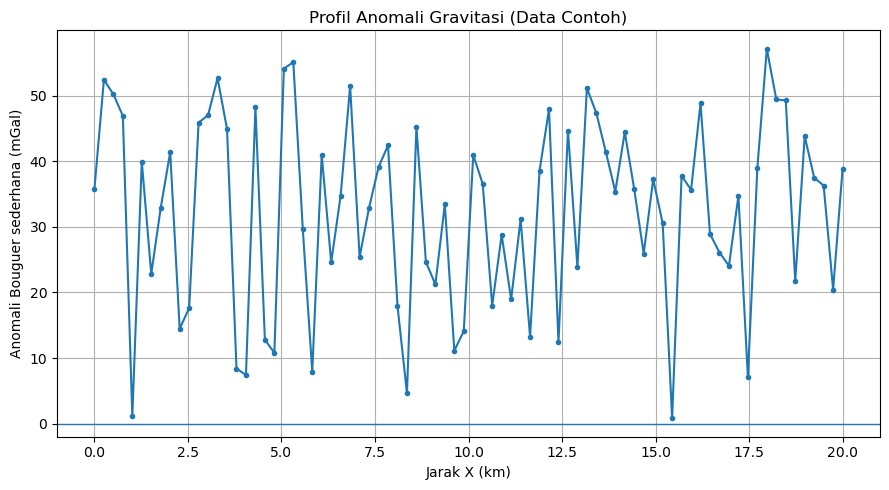

Catatan: ini demonstrasi alur dengan nilai referensi dan koreksi sederhana.
Untuk data lapangan, masukkan gravitasi observasi, gravitasi normal, elevasi,
densitas, lintang, serta koreksi lain yang memang tersedia dan diperlukan.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DATA CONTOH sintetis
np.random.seed(20)
n = 80
df_grav = pd.DataFrame({
    "X_km": np.linspace(0, 20, n),
    "elevasi_m": np.random.uniform(10, 300, n),
    "gravitasi_mGal": 978000 + np.random.normal(0, 3, n)
})
# Parameter contoh, bukan pengganti parameter lapangan
rho = 2.67  # densitas Bouguer dalam g/cm^3
free_air_gradient = 0.3086  # mGal/m
bouguer_factor = 0.04193    # mGal per (m * g/cm^3)

df_grav["koreksi_udara_bebas"] = free_air_gradient * df_grav["elevasi_m"]
df_grav["koreksi_bouguer"] = bouguer_factor * rho * df_grav["elevasi_m"]
# Rumus sederhana: g_obs - g_ref + koreksi udara bebas - koreksi Bouguer
# g_ref di sini hanya nilai referensi contoh
g_ref = 978000
df_grav["anomali_bouguer_sederhana"] = (df_grav["gravitasi_mGal"] - g_ref
    + df_grav["koreksi_udara_bebas"] - df_grav["koreksi_bouguer"])

print(df_grav.head())
print(df_grav[["anomali_bouguer_sederhana"]].describe())

plt.figure(figsize=(9, 5))
plt.plot(df_grav.X_km, df_grav.anomali_bouguer_sederhana, marker=".")
plt.axhline(0, linewidth=1)
plt.xlabel("Jarak X (km)")
plt.ylabel("Anomali Bouguer sederhana (mGal)")
plt.title("Profil Anomali Gravitasi (Data Contoh)")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Catatan: ini demonstrasi alur dengan nilai referensi dan koreksi sederhana.")
print("Untuk data lapangan, masukkan gravitasi observasi, gravitasi normal, elevasi,")
print("densitas, lintang, serta koreksi lain yang memang tersedia dan diperlukan.")

## Prompt 3 — Pengolahan Data Resistivitas
Tujuan: menghitung resistivitas semu dari resistansi dan faktor geometri K. K harus ditentukan dari konfigurasi dan jarak elektroda yang digunakan.

   spasi_m  resistansi_ohm    K_m  resistivitas_semu_ohm_m
0        1              18   6.28                   113.04
1        2              14  12.57                   175.98
2        3              11  18.85                   207.35
3        4               9  25.13                   226.17
4        5               8  31.42                   251.36
5        6               7  37.70                   263.90


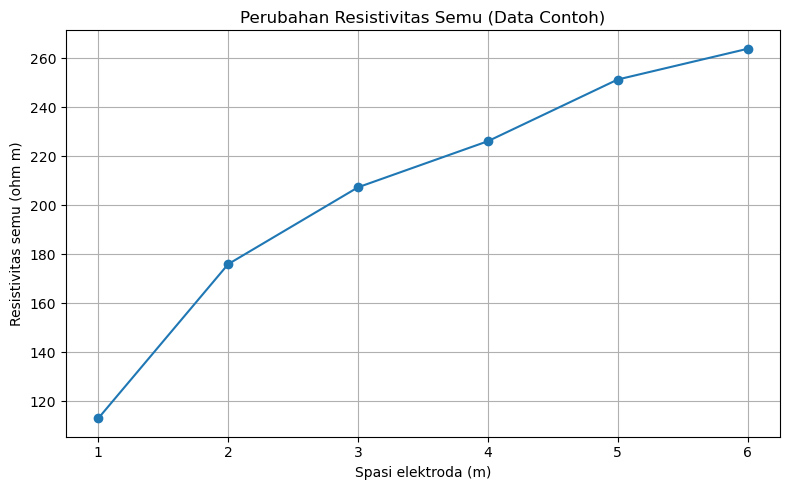

Resistivitas semu dihitung dengan rho_a = K x R.
Spasi elektroda bukan kedalaman secara langsung; kedalaman investigasi bergantung
pada konfigurasi, geometri, dan proses inversi. Jangan menetapkan litologi dari satu nilai saja.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# DATA CONTOH. Nilai K di bawah hanya ilustrasi; hitung sesuai konfigurasi elektroda.
df_res = pd.DataFrame({
    "spasi_m": [1, 2, 3, 4, 5, 6],
    "resistansi_ohm": [18, 14, 11, 9, 8, 7],
    "K_m": [6.28, 12.57, 18.85, 25.13, 31.42, 37.70]
})
df_res["resistivitas_semu_ohm_m"] = df_res["K_m"] * df_res["resistansi_ohm"]
print(df_res)

plt.figure(figsize=(8, 5))
plt.plot(df_res.spasi_m, df_res.resistivitas_semu_ohm_m, marker="o")
plt.xlabel("Spasi elektroda (m)")
plt.ylabel("Resistivitas semu (ohm m)")
plt.title("Perubahan Resistivitas Semu (Data Contoh)")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Resistivitas semu dihitung dengan rho_a = K x R.")
print("Spasi elektroda bukan kedalaman secara langsung; kedalaman investigasi bergantung")
print("pada konfigurasi, geometri, dan proses inversi. Jangan menetapkan litologi dari satu nilai saja.")

## Prompt 4 — Analisis SST dan FFT
Tujuan: membuat grafik anomali SST terhadap waktu dan mencari periode dominan menggunakan FFT. Data sintetis bulanan dipakai sebagai contoh.

     tanggal  anomali_SST_C
0 2006-01-01      -0.109359
1 2006-02-01       0.259927
2 2006-03-01       0.374488
3 2006-04-01       0.762840
4 2006-05-01       0.226021


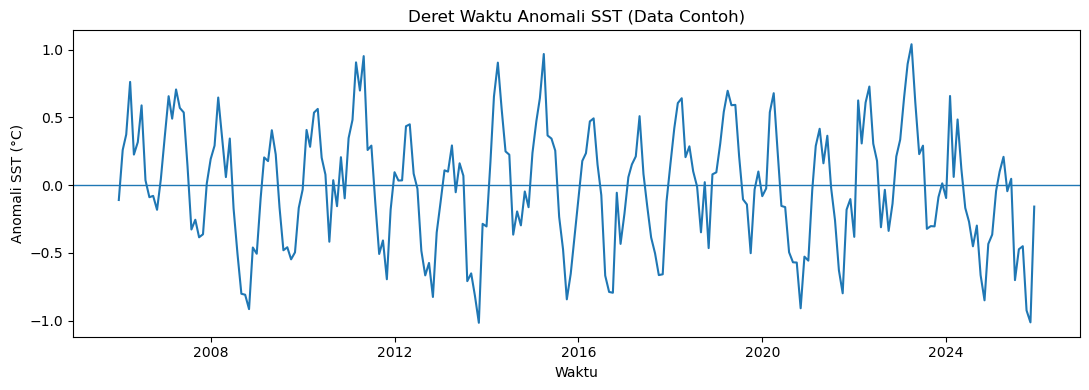

Lima puncak spektrum terbesar:
   frekuensi_siklus_per_bulan  periode_bulan  amplitudo
0                    0.083333      12.000000  60.922690
1                    0.020833      48.000000  31.223465
2                    0.050000      20.000000   7.192767
3                    0.416667       2.400000   7.116514
4                    0.345833       2.891566   5.393048


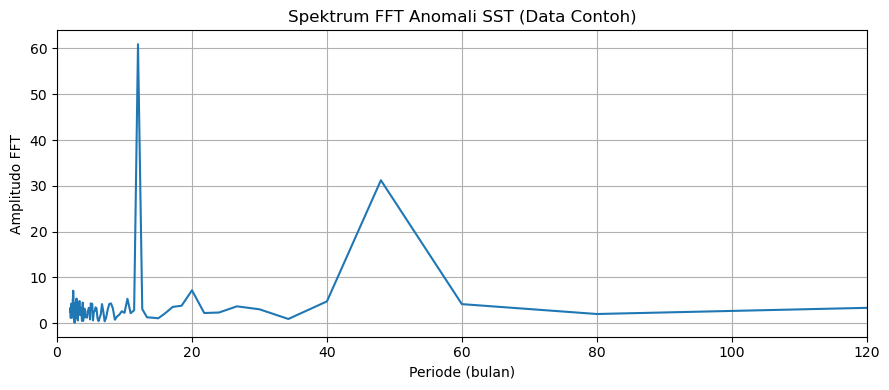

Periode (bulan) = 1 / frekuensi (siklus per bulan).
Puncak FFT menunjukkan periodisitas statistik, bukan bukti langsung fenomena iklim tertentu.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DATA CONTOH anomali SST bulanan selama 20 tahun
np.random.seed(40)
n = 20 * 12
t = np.arange(n)  # interval 1 bulan
sst_anomali = (0.5*np.sin(2*np.pi*t/12) +
               0.25*np.sin(2*np.pi*t/48) +
               np.random.normal(0, 0.18, n))
dates = pd.date_range("2006-01-01", periods=n, freq="MS")
df_sst = pd.DataFrame({"tanggal": dates, "anomali_SST_C": sst_anomali})
print(df_sst.head())

plt.figure(figsize=(11, 4))
plt.plot(df_sst.tanggal, df_sst.anomali_SST_C)
plt.axhline(0, linewidth=1)
plt.xlabel("Waktu")
plt.ylabel("Anomali SST (°C)")
plt.title("Deret Waktu Anomali SST (Data Contoh)")
plt.tight_layout()
plt.show()

# FFT: kurangi rata-rata agar komponen konstan tidak mendominasi
x = df_sst.anomali_SST_C.to_numpy()
x = x - np.mean(x)
fft_values = np.fft.rfft(x)
freq = np.fft.rfftfreq(len(x), d=1)  # siklus per bulan
amplitude = np.abs(fft_values)

# Abaikan frekuensi nol untuk mencari periode
freq_nonzero = freq[1:]
amp_nonzero = amplitude[1:]
period_bulan = 1 / freq_nonzero
idx = np.argsort(amp_nonzero)[::-1][:5]
hasil_fft = pd.DataFrame({
    "frekuensi_siklus_per_bulan": freq_nonzero[idx],
    "periode_bulan": period_bulan[idx],
    "amplitudo": amp_nonzero[idx]
})
print("Lima puncak spektrum terbesar:")
print(hasil_fft)

plt.figure(figsize=(9, 4))
plt.plot(period_bulan, amp_nonzero)
plt.xlim(0, 120)
plt.xlabel("Periode (bulan)")
plt.ylabel("Amplitudo FFT")
plt.title("Spektrum FFT Anomali SST (Data Contoh)")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Periode (bulan) = 1 / frekuensi (siklus per bulan).")
print("Puncak FFT menunjukkan periodisitas statistik, bukan bukti langsung fenomena iklim tertentu.")

## Prompt 5 — Klasifikasi Litologi dari Log Sumur
Tujuan: melatih model klasifikasi sederhana dengan fitur log sumur contoh, lalu mengevaluasi performanya. Data sintetis hanya untuk demonstrasi; hasil tidak mewakili sumur nyata.

Akurasi: 0.933

Laporan Klasifikasi:
               precision    recall  f1-score   support

 Batugamping       1.00      0.85      0.92        13
   Batupasir       0.91      0.94      0.92        31
      Serpih       0.94      0.97      0.95        31

    accuracy                           0.93        75
   macro avg       0.95      0.92      0.93        75
weighted avg       0.94      0.93      0.93        75



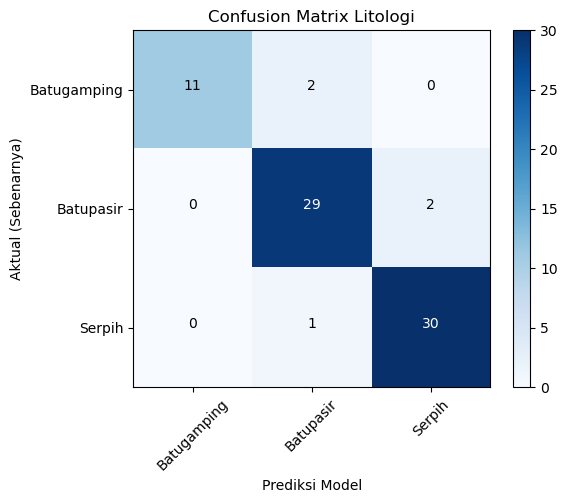

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# 1. DATA SINTETIS
np.random.seed(50)
n = 300
litologi = np.random.choice(["Batupasir", "Serpih", "Batugamping"], size=n, p=[0.4, 0.4, 0.2])
gamma = np.where(litologi == "Serpih", np.random.normal(100, 18, n),
         np.where(litologi == "Batupasir", np.random.normal(55, 15, n), np.random.normal(30, 10, n)))
densitas = np.where(litologi == "Batugamping", np.random.normal(2.65, 0.12, n),
            np.where(litologi == "Batupasir", np.random.normal(2.35, 0.15, n), np.random.normal(2.50, 0.12, n)))
neutron = np.where(litologi == "Serpih", np.random.normal(0.32, 0.06, n),
            np.where(litologi == "Batupasir", np.random.normal(0.22, 0.05, n), np.random.normal(0.12, 0.04, n)))

df_log = pd.DataFrame({"gamma_ray": gamma, "densitas": densitas, "neutron_porosity": neutron, "litologi": litologi})

# Masukkan beberapa missing value (NaN)
for col in ["gamma_ray", "densitas", "neutron_porosity"]:
    df_log.loc[df_log.sample(frac=0.03, random_state=1).index, col] = np.nan

# 2. TRAINING MODEL
X = df_log[["gamma_ray", "densitas", "neutron_porosity"]]
y = df_log["litologi"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
)
model.fit(X_train, y_train)
prediksi = model.predict(X_test)

# Cetak Hasil Teks
print("Akurasi:", round(accuracy_score(y_test, prediksi), 3))
print("\nLaporan Klasifikasi:\n", classification_report(y_test, prediksi, zero_division=0))

# ==========================================
# 3. VISUALISASI SEDERHANA (Matplotlib)
# ==========================================
cm = confusion_matrix(y_test, prediksi, labels=model.classes_)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix Litologi')
plt.colorbar()

tick_marks = np.arange(len(model.classes_))
plt.xticks(tick_marks, model.classes_, rotation=45)
plt.yticks(tick_marks, model.classes_)

# Menampilkan angka di dalam kotak heatmap
thresh = cm.max() / 2.
for i, j in np.ndindex(cm.shape):
    plt.text(j, i, format(cm[i, j], 'd'),
             horizontalalignment="center",
             color="white" if cm[i, j] > thresh else "black")

plt.ylabel('Aktual (Sebenarnya)')
plt.xlabel('Prediksi Model')
plt.tight_layout()
plt.show()

## Catatan penggunaan
1. Jalankan sel dari atas ke bawah.
2. Semua angka pada bagian data contoh dapat diganti dengan data praktikum asli.
3. Periksa nama kolom, satuan, sistem koordinat, dan konfigurasi alat sebelum analisis.
4. Jangan menulis kesimpulan geologi yang lebih pasti daripada yang didukung data.